In [ ]:
import os
import shutil

mactex_path = "/Library/TeX/texbin"
if mactex_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + mactex_path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pde import (
    PDE,
    CartesianGrid,
    FieldCollection,
    MemoryStorage,
    PDEBase,
    PolarSymGrid,
    ScalarField,
)
from pde.backends import get_backend
from pde.trackers import CallbackTracker
from scipy.interpolate import RegularGridInterpolator

plt.rcParams.update(
    {"text.usetex": shutil.which("latex") is not None, "font.family": "serif"}
)


%load_ext autoreload
%autoreload 2
pd.set_option("display.max_rows", 200)
panel_ids = ["A", "B", "C", "D", "E", "F", "G", "H"]
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-3, -3))

# Config and helper functions

In [ ]:
def merge_presets(presets, defaults):
    """Merge each preset dict with default_config; preset values take priority."""
    return {name: {**defaults, **preset} for name, preset in presets.items()}


# dict for simulator/integrator
integration_dict = {
    "outer_radius": 60,
    "num_pts_radius": 1000,
    "t_max": 100,
    "dt": 0.001,
}

# dict for initial population density.
seed_dict = {
    "N_init": 100,  # integral of population density
    "seed_radius": 10,  # threshold/cutoff for initial shape. Usage contingent on init_method below
    "gaussian_sharpness": 2,  # parameter needed for super_gaussian_*** init_methods
    "wave_cutoff": 0.01,  # threshold used for super_gaussian init_method
    "init_method": "gaussian",  # choices are 'gaussian' (default), 'cosine_taper', 'super_gaussian', 'super_gaussian_no_cutoff'
    "K_scaling": 50,
}

# dict for choice of calculating wavefront position, cutoff for wavefront position, and time intervals for which pypde
analysis_dict = {
    "wavefront_method": "effective_carrying_capacity",  # choices enumerated in compute_wavefront_idx dispatcher
    "wavefront_cutoff": 0.1,  # threshold for % height, area, reached by which wavefront radius is defined
    "tracker_time": 0.2,  # results recorded every tracker_time seconds
}

# setting for "baseline" archetype
default_config = {
    "r": 0.5,
    # 'K': 50,
    "D": 0.35,
    "a": 0.03,
    "m0": 0.25,
    "h": 0.05,
    "b_r": 0.015,
    "b_k": 0.015,
    "escape": 0.5,
    "E_r0": 0.05,
    "E_k0": 0.05,
}
preset_dicts = {
    "baseline": {"description": "default config"},
    "high motility + weak niche": {
        "description": "High growth and high motility. Rapid front propagation with weak immune containment.",
        "r": 0.95,
        "D": 0.9,
        "h": 0.1,
        "b_r": 0.005,
        "b_k": 0.005,
        "escape": 0.75,
    },
    "high predation/immune pressure": {
        "description": "Strong immune attack, low escape. The lesion struggles to establish and may regress.",
        "m0": 0.4,
        "a": 0.2,
        "h": 0.02,
        "b_r": 0.01,
        "b_k": 0.01,
        "escape": 0.1,
    },
    "strong niche construction": {
        "description": "Strong ecological engineering. Niche construction quickly suppresses immune pressure and lifts carrying capacity.",
        "r": 0.13,
        "D": 0.15,
        "h": 0.04,
        "b_r": 0.1,
        "b_k": 0.1,
    },
}
bcs = {"derivative": 0}


def rolling_area(u_init, r_coords):
    """Cumulative area of u_init up to each radius."""
    dr = np.gradient(r_coords)
    return np.cumsum(2 * np.pi * r_coords * u_init * dr)


def compute_wavefront_idx_by_height(u_curr, r_coords, cutoff, e_field):
    """DEPRECATED: Wavefront position judged from max(u_curr)"""
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * np.max(u_curr))
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1


def compute_wavefront_idx_by_area(u_curr, r_coords, cutoff, e_field):
    """DEPRECATED: Wavefront position judged by cumulative area crossing threshold (1-cutoff)*total"""
    roll = rolling_area(u_curr, r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1 - cutoff) * total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1


def compute_wavefront_idx_by_carrying_capacity(u_curr, r_coords, cutoff, e_field):
    """DEPRECATED: Wavefront position judged from u_curr scaled by bare carrying capacity"""
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * default_config["K"])
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1


def compute_wavefront_idx_by_effective_carrying_capacity(
    u_curr, r_coords, cutoff, e_field
):
    """Wavefront position judged from cutoff with respect to u_curr scaled by the effective carrying capacity. r_val is interpolated for smoother estimation"""
    threshold = cutoff * default_config["K"] * e_field
    post_cutoff_idx = np.flatnonzero(u_curr < threshold)[0]
    if post_cutoff_idx == 0:
        return r_coords[0], 0
    prev_cutoff_idx = post_cutoff_idx - 1
    r_val = r_coords[prev_cutoff_idx] + (
        (r_coords[post_cutoff_idx] - r_coords[prev_cutoff_idx])
        * (threshold[post_cutoff_idx] - u_curr[prev_cutoff_idx])
        / (u_curr[post_cutoff_idx] - u_curr[prev_cutoff_idx])
    )
    return r_val, post_cutoff_idx


def compute_wavefront_idx_by_effective_carrying_capacity_area(
    u_curr, r_coords, cutoff, e_field
):
    """DEPRECATED: Wavefront position estimated by area cutoff, where area is u_curr scaled by effective carrying capacity"""
    roll = rolling_area(u_curr / (default_config["K"] * e_field), r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1 - cutoff) * total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1


def compute_wavefront_idx(config, u_curr, r_coords, e_field):
    method_dispatch = {
        # "height": compute_wavefront_idx_by_height,
        # "area": compute_wavefront_idx_by_area,
        # "carrying_capacity": compute_wavefront_idx_by_carrying_capacity,
        "effective_carrying_capacity": compute_wavefront_idx_by_effective_carrying_capacity,
        # "effective_carrying_capacity_area": compute_wavefront_idx_by_effective_carrying_capacity_area,
    }
    chosen_method = method_dispatch.get(config["wavefront_method"])
    return chosen_method(u_curr, r_coords, config["wavefront_cutoff"], e_field)


def compute_participation_area(u_curr):
    total_mass = u_curr.integral
    squared_mass = (u_curr**2).integral
    effective_area = (total_mass**2) / squared_mass
    return effective_area


def build_initial_N(config):
    seed_params = config["seed"]
    integration_params = config["integration"]
    grid = PolarSymGrid(
        radius=integration_params["outer_radius"],
        shape=integration_params["num_pts_radius"],
    )
    r_coords = grid.axes_coords[0]

    def super_gaussian():
        exponent = 2 * seed_params["gaussian_sharpness"]
        u_init = np.exp(-((r_coords / seed_params["seed_radius"]) ** exponent))
        cutoff_idx = compute_wavefront_idx_by_height(
            u_init, r_coords, seed_params["wave_cutoff"]
        )
        u_init[cutoff_idx + 1 :] = 0
        return u_init

    def cosine_taper():
        u_init = 1 - (r_coords / seed_params["seed_radius"])
        u_init[u_init < 0] = 0
        return u_init

    def super_gaussian_no_cutoff():
        exponent = 2 * seed_params["gaussian_sharpness"]
        u_init = np.exp(-((r_coords / seed_params["seed_radius"]) ** exponent))
        return u_init

    def gaussian():
        u_init = np.exp(-((r_coords / seed_params["seed_radius"]) ** 2))
        return u_init

    # dispatch
    method_dispatch = {
        "super_gaussian": super_gaussian,
        "cosine_taper": cosine_taper,
        "super_gaussian_no_cutoff": super_gaussian_no_cutoff,
        "gaussian": gaussian,
    }
    chosen_method = method_dispatch.get(seed_params["init_method"])
    u_init = chosen_method()
    total = rolling_area(u_init, r_coords)[-1]
    if total == 0:
        raise ValueError("The initial distribution is zero after applying the cutoff.")
    u_init *= seed_params["N_init"] / total  # normalizing area to equal N_init
    u_field = ScalarField(grid, data=u_init, label="N")
    return u_field, r_coords

In [26]:
scenario_wavefront_speed = []
scenario_final_profiles = []
u_field, r_coords = build_initial_N(
    {"integration": integration_dict, "seed": seed_dict}
)
default_config["K"] = (
    np.max(u_field.data) * seed_dict["K_scaling"]
)  # K is set to K_scaling x the largest value of the initial population density
merged_presets = merge_presets(preset_dicts, default_config)
config_dict = {
    "integration": integration_dict,
    "seed": seed_dict,
    "bcs": bcs,
    "presets": merged_presets,
    "analysis": analysis_dict,
}

for preset_name, preset_config in config_dict[
    "presets"
].items():  # iterating over archetypes
    print(f"Running simulation for preset: {preset_name}")
    Er_init = np.ones_like(u_field.data) * preset_config["E_r0"]
    Ek_init = np.ones_like(u_field.data) * preset_config["E_k0"]
    Er_field = ScalarField(u_field.grid, data=Er_init, label="E_r")
    Ek_field = ScalarField(u_field.grid, data=Ek_init, label="E_k")
    state = FieldCollection([u_field, Er_field, Ek_field])

    diff = preset_config["D"]
    r = preset_config["r"]
    kappa = preset_config["K"]
    m_0 = preset_config["m0"]
    escape = preset_config["escape"]
    h = preset_config["h"]
    a = preset_config["a"]
    b_r = preset_config["b_r"]
    b_k = preset_config["b_k"]
    diffusion = f"{diff} * laplace(N)"
    logistic = f"+ {r} * E_r * N * (1 - (N / (E_k * {kappa})))"
    m_eff = f"({m_0} / (1 + {escape} * ((E_r + E_k)/2)))"
    predation = f"- {m_eff} * {a} * N / (1 + {h} * {a} * N)"
    equations = {
        "N": diffusion + logistic + predation,
        "E_r": f"(1 - E_r) * (1 - exp(- {b_r} * N))",
        "E_k": f"(1 - E_k) * (1 - exp(- {b_k} * N))",
    }
    pde_system = PDE(equations, bc=config_dict["bcs"])
    storage = MemoryStorage()
    pde_system.solve(
        state,
        t_range=config_dict["integration"]["t_max"],
        dt=config_dict["integration"]["dt"],
        tracker=["progress", storage.tracker(config_dict["analysis"]["tracker_time"])],
        adaptive=True,
    )
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        analysis_dict = config_dict["analysis"]
        e_field = storage[t_idx][2].data
        r_val, idx = compute_wavefront_idx(analysis_dict, curr_u, r_coords, e_field)
        # at each tracker time value, save the wavefront position, the total population, and the participation area (unused)
        scenario_wavefront_speed.append(
            (
                preset_name,
                time,
                np.max(curr_u),
                r_val,
                rolling_area(preset_config["E_k0"] * curr_u / e_field, r_coords)[-1],
                compute_participation_area(storage[t_idx][0]),
            )
        )
    print(f"Saving results for preset: {preset_name}")
    # save final fields
    final_collection = storage[-1]
    final_Er = final_collection[1].data
    final_Ek = final_collection[2].data
    final_N = final_collection[0].data / (kappa * final_Ek)
    scenario_final_profiles.append((preset_name, final_N, (final_Er + final_Ek) / 2))

Running simulation for preset: baseline


100%|██████████| 100.0/100.0 [00:02<00:00, 37.02it/s]     


Saving results for preset: baseline
Running simulation for preset: high motility + weak niche


100%|██████████| 100.0/100.0 [00:02<00:00, 33.90it/s]     


Saving results for preset: high motility + weak niche
Running simulation for preset: high predation/immune pressure


100%|██████████| 100.0/100.0 [00:03<00:00, 33.29it/s]     


Saving results for preset: high predation/immune pressure
Running simulation for preset: strong niche construction


100%|██████████| 100.0/100.0 [00:02<00:00, 39.52it/s]     

Saving results for preset: strong niche construction


# Uncoupled PDE results

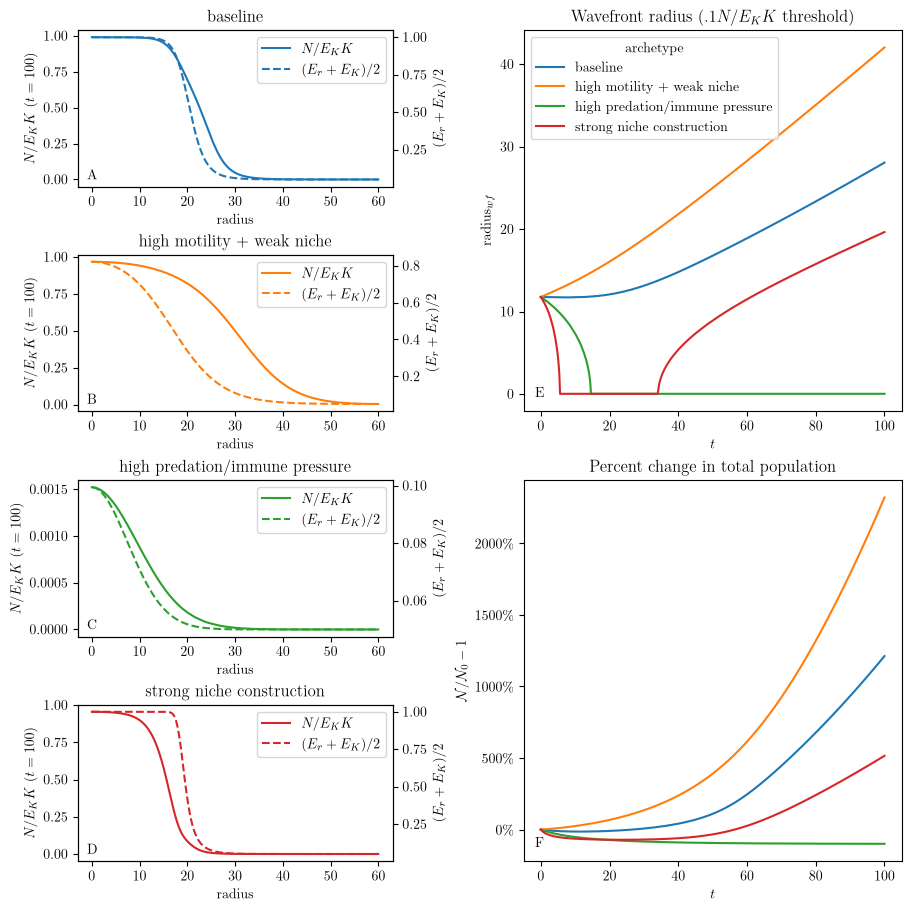

In [39]:
df = pd.DataFrame(
    scenario_wavefront_speed, columns=["archetype", "t", "u_max", "r", "N", "eff_area"]
)
df["N_init"] = config_dict["seed"]["N_init"]
df["N_perc"] = (df["N"] / df["N_init"] - 1) * 100
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
scenarios = [s for s, _, _ in scenario_final_profiles]
colors = sns.color_palette("tab10", n_colors=len(scenarios))
palette = dict(zip(scenarios, colors))
for i, (scenario, final_N, final_Er) in enumerate(scenario_final_profiles):
    ax = fig.add_subplot(gs[i, 0])
    ax_right = ax.twinx()

    (line_n,) = ax.plot(r_coords, final_N, color=palette[scenario], label="$N$")
    (line_er,) = ax_right.plot(
        r_coords,
        final_Er,
        color=palette[scenario],
        linestyle="--",
    )

    ax.set_title(scenario)
    ax.set_xlabel("radius")
    ax.set_ylabel("$N/E_{K}K$" + " $(t=100)$")
    ax_right.set_ylabel(r"$(E_{r}+E_{K})/2$")
    ax.legend([line_n, line_er], ["$N/E_{K}K$", r"$(E_r + E_K)/2$"], loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df, x="t", y="r", hue="archetype", ax=ax_wavefront)
ax_wavefront.set(
    ylabel="radius" + "$_{wf}$",
    xlabel="$t$",
    title="Wavefront radius " + "$(.1 N/E_{K}K$ " + "threshold)",
)

ax_population = fig.add_subplot(gs[2:, 1])
ax_population.yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(xmax=100)
)
sns.lineplot(data=df, x="t", y="N_perc", hue="archetype", ax=ax_population)
ax_population.set(
    ylabel="$\\mathcal{N} / \\mathcal{N}_{0} -1$",
    xlabel="$t$",
    title="Percent change in total population",
)
ax_population.get_legend().remove()

# Exclude the twinx axes by keeping only the first axes at each panel position.
panel_axes = []
panel_positions = []
for panel_ax in fig.axes:
    bounds = panel_ax.get_position().bounds
    if not any(np.allclose(bounds, pos) for pos in panel_positions):
        panel_axes.append(panel_ax)
        panel_positions.append(bounds)

for panel_ax, panel_id in zip(panel_axes, panel_ids):
    panel_ax.text(
        0.03,
        0.03,
        panel_id,
        transform=panel_ax.transAxes,
        ha="left",
        va="bottom",
        fontweight="bold",
    )
plt.show()

# Coupled (hybrid) PDE 


In [79]:
def logistic_derivs(z, k):
    """Return f-strings for L, L', ..., L^(5) of L(u) = 1/(1+exp(-k u)) at u = z. Here z is the mean trait at the given position."""
    L = f"(1/(1 + exp(-{k}*{z})))"
    s = f"({L}*(1 - {L}))"
    return (
        L,
        f"({k}*{s})",
        f"({k}**2*{s}*(1 - 2*{L}))",
        f"({k}**3*{s}*(1 - 6*{s}))",
        f"({k}**4*{s}*(1 - 2*{L})*(1 - 12*{s}))",
        f"({k}**5*{s}*(1 - 30*{s} + 120*{s}**2))",
    )


class HybridPDE(PDEBase):
    """Hybrid model with fields (N, E_r, E_k, z0, z1, z2) and the build_hybrid_rhs parameters."""

    def __init__(self, params, bc=None):
        super().__init__()
        for name in ("theta_r", "theta_K", "escape_public"):
            if not 0.0 <= params[name] <= 1.0:
                raise ValueError(f"{name} must lie in [0, 1]")
        self.params = dict(params)
        self.bc = {"derivative": 0} if bc is None else bc

    def evolution_rate(self, state, t=0):
        """Uncompiled evaluation of the same right-hand side (numba grid operators), as a FieldCollection."""
        rhs = self.make_evolution_rate(state, backend=get_backend("numba"))
        out = state.copy(label="evolution rate")
        out.data[:] = rhs(state.data, t)
        return out

    def make_evolution_rate(self, state, backend):
        p = self.params
        r, K, a, h, m0, eps = p["r"], p["K"], p["a"], p["h"], p["m0"], p["eps"]
        D0, br0, bK0 = p["D0"], p["br0"], p["bK0"]
        k0, k1, k2 = p["k0"], p["k1"], p["k2"]
        V0, V1, V2 = p["V0"], p["V1"], p["V2"]
        theta_r, theta_K = p["theta_r"], p["theta_K"]
        w = 1.0 - p["escape_public"]
        N_eps = p["N_eps"]
        N_c = float(p.get("N_c", 1.0))

        grid = state.grid
        ops = {"backend": backend, "dtype": state.dtype}
        laplace = grid.make_operator("laplace", bc=self.bc, **ops)
        gradient = grid.make_operator("gradient", bc=self.bc, **ops)

        def ecology(N, E_r, E_k):
            """Shared ecology terms at the field values (H, eta, kappa, lambda, crowding, g)."""
            H = a / (1.0 + a * h * N)
            q = 1.0 + eps * 0.5 * (E_r + E_k)
            meff = m0 / q
            eta = m0 * eps * H / (2.0 * q**2)  # -0.5 m_E H
            kap = m0 * eps**2 * H / (2.0 * q**3)  # 0.25 m_EE H
            lam = -3.0 * m0 * eps**3 * H / (4.0 * q**4)  # 0.125 m_EEE H
            crowd = 1.0 - N / (K * E_k)
            g = r * E_r * crowd - meff * H
            Gr = r * crowd + w * eta  # dG/dE_r^exp
            GK = r * E_r * N / (K * E_k**2) + w * eta  # dG/dE_K^exp
            return g, Gr, GK, kap, lam

        if backend.name == "numba":
            ecology = backend.compile_function(ecology)

        def pde_rhs(state_data, t=0):
            N, E_r, E_k = state_data[0], state_data[1], state_data[2]
            gam = N / (N + N_c)  # variance gate gamma(N)
            V0g, V1g, V2g = (
                V0 * gam,
                V1 * gam,
                V2 * gam,
            )  # gated variances (equal to V_i when off)
            z0, z1, z2 = state_data[3], state_data[4], state_data[5]
            lap0, lap1, lap2 = (laplace(z0), laplace(z1), laplace(z2))
            gN, g0 = gradient(N), gradient(z0)
            g1, g2 = gradient(z1), gradient(z2)

            # sigmoid L(k z) and derivatives up to L^(5), computed once per grid point
            L0 = 1.0 / (1.0 + np.exp(-k0 * z0))
            s0 = L0 * (1.0 - L0)
            L1 = 1.0 / (1.0 + np.exp(-k1 * z1))
            s1 = L1 * (1.0 - L1)
            L2 = 1.0 / (1.0 + np.exp(-k2 * z2))
            s2 = L2 * (1.0 - L2)
            D = D0 * L0
            Dp = D0 * k0 * s0
            Dpp = D0 * k0**2 * s0 * (1.0 - 2.0 * L0)
            Dppp = D0 * k0**3 * s0 * (1.0 - 6.0 * s0)
            br = br0 * L1
            brp = br0 * k1 * s1
            brpp = br0 * k1**2 * s1 * (1.0 - 2.0 * L1)
            brppp = br0 * k1**3 * s1 * (1.0 - 6.0 * s1)
            bK = bK0 * L2
            bKp = bK0 * k2 * s2
            bKpp = bK0 * k2**2 * s2 * (1.0 - 2.0 * L2)
            bKppp = bK0 * k2**3 * s2 * (1.0 - 6.0 * s2)

            # O(V) mean coefficients
            bbr = br + 0.5 * V1g * brpp
            bbK = bK + 0.5 * V2g * bKpp
            Db = D + 0.5 * V0g * Dpp
            Dbp = Dp + 0.5 * V0g * Dppp

            g, Gr, GK, kap, lam = ecology(N, E_r, E_k)
            # retained-benefit factor A_j: headroom (1 - E_j) or stock E_j (1 - E_j)
            Ar = theta_r * E_r * (1.0 - E_r) / bbr
            AK = theta_K * E_k * (1.0 - E_k) / bbK
            invN = 1.0 / (N + N_eps)

            # derivatives of G_j with respect to the niche fields
            dGr_r = -(w**2) * kap
            d2Gr_r = -(w**3) * lam
            d2Gr_K = -2.0 * r * N / (K * E_k**3) - w**3 * lam
            dGK_K = -2.0 * r * E_r * N / (K * E_k**3) - w**2 * kap
            d2GK_K = 6.0 * r * E_r * N / (K * E_k**4) - w**3 * lam
            d2GK_r = -(w**3) * lam

            # mean fitness (Jensen term) and full selection terms <dG/dchi_j> to O(V)
            Gbar = g + 0.5 * (
                V1g * Ar**2 * brp**2 * dGr_r + V2g * AK**2 * bKp**2 * dGK_K
            )
            sel1 = Ar * (
                brp * Gr
                + V1g
                * (
                    0.5 * brppp * Gr
                    + Ar * brp * brpp * dGr_r
                    + 0.5 * Ar**2 * brp**3 * d2Gr_r
                )
                + 0.5 * V2g * AK**2 * bKp**2 * brp * d2Gr_K
            )
            sel2 = AK * (
                bKp * GK
                + V2g
                * (
                    0.5 * bKppp * GK
                    + AK * bKp * bKpp * dGK_K
                    + 0.5 * AK**2 * bKp**3 * d2GK_K
                )
                + 0.5 * V1g * Ar**2 * brp**2 * bKp * d2GK_r
            )

            dot_N0 = np.sum(gN * g0, axis=0)
            out = np.empty_like(state_data)
            gDb = gradient(Db)
            out[0] = laplace(Db * N) + N * Gbar  # evolution of N
            out[1] = (1.0 - E_r) * (1.0 - np.exp(-bbr * N))  # evolution of E_r
            out[2] = (1.0 - E_k) * (1.0 - np.exp(-bbK * N))  # evolution of E_k
            out[3] = (
                Db * lap0
                + 2.0 * Db * dot_N0 * invN
                + 2.0 * np.sum(gDb * g0, axis=0)
                + laplace(N * V0g * Dbp) * invN
            )  # evolution of trait pertaining to D
            out[4] = (
                V1g * sel1
                + Db * lap1
                + 2.0 * Db * np.sum(gN * g1, axis=0) * invN
                + 2.0 * np.sum(gDb * g1, axis=0)
            )  # evolution of traint pertaining to b_r
            out[5] = (
                V2g * sel2
                + Db * lap2
                + 2.0 * Db * np.sum(gN * g2, axis=0) * invN
                + 2.0 * np.sum(gDb * g2, axis=0)
            )  # evolution of trait pertaining to b_K
            return out

        return pde_rhs

In [80]:
hybrid_dict = {
    "k": (4, 4, 4),  # sigmoid steepness for z0 (motility), z1 (b_r), z2 (b_K)
    "V": (
        0.01,
        0.01,
        0.01,
    ),  # standing trait variances V0, V1, V2 (low-variance closure)
    "D_max_factor": 2.0,  # plateau D0 = D_max_factor * D, so the run starts at the preset D
    "b_max_factor": 2.0,  # plateaus b_j0 = b_max_factor * b_j, so the run starts at the preset b_j
    "theta": (
        0.5,
        0.5,
    ),  # retained shares theta_r, theta_K; (0, 0) gives the neutral hybrid
    "escape_public": 0.0,  # omega; 0.0 means escape follows the experienced niche
    "N_eps": 1e-3,  # regulariser for the ln N term
    "N_c": 1e-4,  # gate half-saturation density (units of N) for the variance gate
}


def build_hybrid_params(preset, traits):
    """Map a config_dict preset onto HybridPDE parameters.

    build_hybrid_rhs has no gate: drop 'variance_gate' and 'N_c' before passing these to it.
    """
    k0, k1, k2 = traits["k"]
    V0, V1, V2 = traits["V"]
    theta_r, theta_K = traits["theta"]
    return {
        "r": preset["r"],
        "K": preset["K"],
        "a": preset["a"],
        "h": preset["h"],
        "m0": preset["m0"],
        "eps": preset["escape"],
        "D0": traits["D_max_factor"] * preset["D"],
        "br0": traits["b_max_factor"] * preset["b_r"],
        "bK0": traits["b_max_factor"] * preset["b_k"],
        "k0": k0,
        "k1": k1,
        "k2": k2,
        "V0": V0,
        "V1": V1,
        "V2": V2,
        "theta_r": theta_r,
        "theta_K": theta_K,
        "escape_public": traits["escape_public"],
        "N_eps": traits["N_eps"],
        "N_c": traits["N_c"],
    }


def build_hybrid_state(config, preset, params):
    """Initial N from build_initial_N; E fields at E_r0, E_k0; uniform z so D, b_r, b_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    grid = u_field.grid

    def z_for(value, plateau, k):
        p = value / plateau
        return np.log(p / (1 - p)) / k

    z_init = (
        z_for(preset["D"], params["D0"], params["k0"]),
        z_for(preset["b_r"], params["br0"], params["k1"]),
        z_for(preset["b_k"], params["bK0"], params["k2"]),
    )
    Er_field = ScalarField(
        grid, data=np.full_like(u_field.data, preset["E_r0"]), label="E_r"
    )
    Ek_field = ScalarField(
        grid, data=np.full_like(u_field.data, preset["E_k0"]), label="E_k"
    )
    z_fields = [
        ScalarField(grid, data=np.full_like(u_field.data, z), label=f"z{i}")
        for i, z in enumerate(z_init)
    ]
    return FieldCollection([u_field, Er_field, Ek_field] + z_fields), r_coords


def sigmoid_value(z, k, plateau):
    """plateau*L(z)"""
    return plateau / (1 + np.exp(-k * z))

In [81]:
hybrid_scenario_params = {}
hybrid_scenario_wavefront_speeds = []
hybrid_scenario_final_profiles = []
for preset_name, preset_config in config_dict["presets"].items():
    print(f"Running hybrid model for preset: {preset_name}")
    params = build_hybrid_params(preset_config, hybrid_dict)

    hybrid_scenario_params[preset_name] = params
    pde_system = HybridPDE(params, bc=config_dict["bcs"])
    state, r_coords = build_hybrid_state(config_dict, preset_config, params)
    e_field_init = state[2].data[0]
    storage = MemoryStorage()
    pde_system.solve(
        state,
        t_range=config_dict["integration"]["t_max"],
        dt=config_dict["integration"]["dt"],
        tracker=["progress", storage.tracker(config_dict["analysis"]["tracker_time"])],
        adaptive=True,
        backend="numba",
    )
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        e_field = storage[t_idx][2].data
        r_val, idx = compute_wavefront_idx(
            config_dict["analysis"], curr_u, r_coords, e_field
        )
        hybrid_scenario_wavefront_speeds.append(
            (
                preset_name,
                time,
                r_val,
                rolling_area(e_field_init * curr_u / e_field, r_coords)[-1],
                compute_participation_area(storage[t_idx][0]),
            )
        )
    final = storage[-1]
    final_Er = final[1].data
    final_Ek = final[2].data
    final_N = final[0].data
    final_D = sigmoid_value(final[3].data, params["k0"], params["D0"])
    final_br = sigmoid_value(final[4].data, params["k1"], params["br0"])
    final_bK = sigmoid_value(final[5].data, params["k2"], params["bK0"])
    final_area = rolling_area(final[0].data, r_coords)[-1]
    hybrid_scenario_final_profiles.append(
        (
            preset_name,
            final_N,
            final_D / (params["D0"] / 2) - 1,
            final_br / (params["br0"] / 2) - 1,
            final_bK / (params["bK0"] / 2) - 1,
        )
    )

Running hybrid model for preset: baseline


Initializing:   0%|          | 0/100.0 [00:00<?, ?it/s]

100%|██████████| 100.0/100.0 [00:12<00:00,  8.12it/s]       


Running hybrid model for preset: high motility + weak niche


100%|██████████| 100.0/100.0 [00:15<00:00,  6.43it/s]        


Running hybrid model for preset: high predation/immune pressure


100%|██████████| 100.0/100.0 [00:13<00:00,  7.17it/s]        


Running hybrid model for preset: strong niche construction


100%|██████████| 100.0/100.0 [00:11<00:00,  8.64it/s]       


In [82]:
heatmap_tracker_time = 1.0
heatmap_preset_name = "baseline"
heatmap_preset = config_dict["presets"][heatmap_preset_name]
heatmap_params = build_hybrid_params(heatmap_preset, hybrid_dict)
heatmap_pde = HybridPDE(heatmap_params, bc=config_dict["bcs"])
print(heatmap_params)
heatmap_state, r_coords = build_hybrid_state(
    config_dict, heatmap_preset, heatmap_params
)
heatmap_storage = MemoryStorage()
heatmap_pde.solve(
    heatmap_state,
    t_range=config_dict["integration"]["t_max"],
    dt=config_dict["integration"]["dt"],
    tracker=["progress", heatmap_storage.tracker(heatmap_tracker_time)],
    adaptive=True,
    backend="numba",
)

heatmap_times = np.array(heatmap_storage.times)
# arrays of shape (n_times, n_radii)
heatmap_D = np.array(
    [
        100
        * (
            sigmoid_value(s[3].data, heatmap_params["k0"], heatmap_params["D0"])
            / heatmap_preset["D"]
            - 1
        )
        for s in heatmap_storage
    ]
)
heatmap_br = np.array(
    [
        100
        * (
            sigmoid_value(s[4].data, heatmap_params["k1"], heatmap_params["br0"])
            / heatmap_preset["b_r"]
            - 1
        )
        for s in heatmap_storage
    ]
)
heatmap_bK = np.array(
    [
        100
        * (
            sigmoid_value(s[5].data, heatmap_params["k2"], heatmap_params["bK0"])
            / heatmap_preset["b_k"]
            - 1
        )
        for s in heatmap_storage
    ]
)
heatmap_N = np.array([s[0].data for s in heatmap_storage])


{'r': 0.5, 'K': np.float64(15.915303324174578), 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'br0': 0.03, 'bK0': 0.03, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'N_c': 0.0001}


100%|██████████| 100.0/100.0 [00:13<00:00,  7.66it/s]        


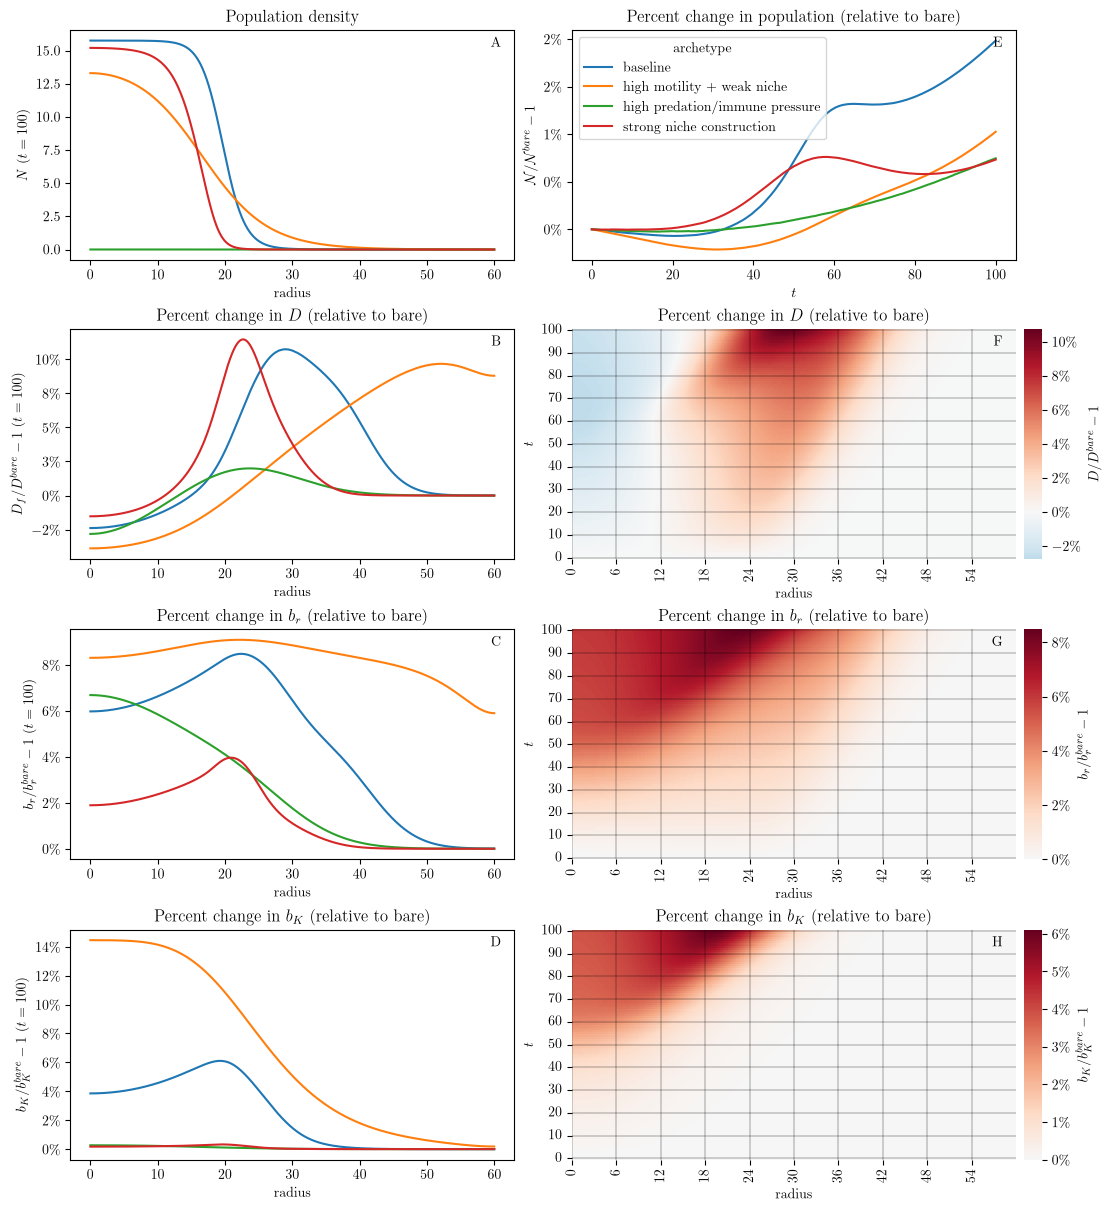

In [83]:
df_hybrid = pd.DataFrame(
    hybrid_scenario_wavefront_speeds, columns=["archetype", "t", "r", "N", "eff_area"]
)
df_hybrid["N_init"] = config_dict["seed"]["N_init"]
df_hybrid["N_perc"] = df_hybrid["N"] / df_hybrid["N_init"]
df_hybrid = df_hybrid.merge(
    df.rename(columns={"r": "base_r", "N_perc": "base_N_perc", "N": "base_N"}),
    how="left",
    on=["archetype", "t"],
)
df_hybrid["r_perc_base"] = 100 * (df_hybrid["r"] / df_hybrid["base_r"] - 1)
df_hybrid["N_perc_base"] = (df_hybrid["N"] / df_hybrid["base_N"] - 1) * 100
hybrid_scenarios = [profile[0] for profile in hybrid_scenario_final_profiles]
hybrid_palette = dict(
    zip(hybrid_scenarios, sns.color_palette("tab10", n_colors=len(hybrid_scenarios)))
)
fig = plt.figure(figsize=(11, 12), constrained_layout=True)
gs = fig.add_gridspec(4, 3, width_ratios=[1, 1, 0.04])
profile_panels = [
    ((1,), ("$N$" + " $(t=100)$",), "Population density"),
    (
        (2,),
        ("$D_f/D^{bare}-1$" + " $(t=100)$",),
        "Percent change in " + "$D$" + " (relative to bare)",
    ),
    (
        (3,),
        ("$b_{r}/b_{r}^{bare}-1$" + " $(t=100)$",),
        "Percent change in " + "$b_{r}$" + " (relative to bare)",
    ),
    (
        (4,),
        ("$b_{K}/b_{K}^{bare}-1$" + " $(t=100)$",),
        "Percent change in " + "$b_{K}$" + " (relative to bare)",
    ),
]
for row, (col_idxs, labels, title) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    if row > 0:
        ax.yaxis.set_major_formatter(
            plt.matplotlib.ticker.PercentFormatter(xmax=1, decimals=0)
        )
    for profile in hybrid_scenario_final_profiles:
        for col_idx, label, style in zip(col_idxs, labels, ("-", "--")):
            ax.plot(
                r_coords,
                profile[col_idx],
                color=hybrid_palette[profile[0]],
                linestyle=style,
            )
    ax.set(xlabel="radius", ylabel=", ".join(labels), title=title)
    if len(col_idxs) > 1:
        # line style legend only; preset colours are in the wavefront legend
        style_handles = [
            plt.Line2D([], [], color="0.3", linestyle=style) for style in ("-", "--")
        ]
        ax.legend(style_handles, labels, loc="center right", fontsize="small")


ax_population = fig.add_subplot(gs[0, 1])
ax_population.yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(xmax=100, decimals=0)
)
sns.lineplot(
    data=df_hybrid,
    x="t",
    y="N_perc_base",
    hue="archetype",
    palette=hybrid_palette,
    ax=ax_population,
)
ax_population.set(
    ylabel=r"$\mathcal{N} / \mathcal{N}^{bare} -1 $",
    xlabel="$t$",
    title=r"Percent change in population (relative to bare)",
)
heatmap_panels = [
    (
        heatmap_D,
        heatmap_preset["D"],
        "$D/D^{bare}-1$",
        "Percent change in " + "$D$" + " (relative to bare)",
    ),
    (
        heatmap_br,
        heatmap_preset["b_r"],
        "$b_{r}/b_{r}^{bare}-1$",
        "Percent change in " + "$b_{r}$" + " (relative to bare)",
    ),
    (
        heatmap_bK,
        heatmap_preset["b_k"],
        "$b_{K}/b_{K}^{bare}-1$",
        "Percent change in " + "$b_{K}$" + " (relative to bare)",
    ),
]
for row, (values, base_value, label, title) in enumerate(heatmap_panels, start=1):
    ax = fig.add_subplot(gs[row, 1])
    cbar_ax = fig.add_subplot(gs[row, 2])
    rel = pd.DataFrame(
        values, index=np.round(heatmap_times, 0), columns=np.round(r_coords, 3)
    )
    sns.heatmap(
        rel,
        cmap="RdBu_r",
        center=0,
        ax=ax,
        cbar_ax=cbar_ax,
        xticklabels=100,
        yticklabels=10,
        cbar_kws={"label": label},
    )
    cbar_ax.yaxis.set_major_formatter(
        plt.matplotlib.ticker.PercentFormatter(xmax=100, decimals=0)
    )
    ax.set_xticklabels(
        [f"{float(label.get_text()):.0f}" for label in ax.get_xticklabels()]
    )
    ax.set_yticklabels(
        [f"{float(label.get_text()):.0f}" for label in ax.get_yticklabels()]
    )
    ax.grid(which="major", color="black", linewidth=0.25)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.invert_yaxis()  # t increases upward
    ax.tick_params(axis="x", labelrotation=90)
    ax.set(xlabel="radius", ylabel="$t$", title=title)


panel_axes = [
    ax
    for ax in fig.axes
    if ax.get_subplotspec().colspan.start != 2  # exclude colorbar axes
]
for ax, panel_id in zip(panel_axes, panel_ids):
    ax.text(
        0.97,
        0.97,
        panel_id,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontweight="bold",
    )

plt.show()

# Coupled (hybrid) PDE on a 2D Cartesian grid

In [ ]:
cartesian_dict = {
    "half_width": config_dict["integration"]["outer_radius"],  # domain [-L, L]^2
    "num_pts_axis": 481,  # grid points per axis; spacing 2L/n (0.25 at L = 60)
    "n_angles": 128,  # rays for the front radius R(theta)
    "n_modes": 8,  # Fourier modes of R(theta) reported, m = 1..n_modes
    "diag_interval": 1.0,  # time between population and front diagnostics
    "snapshot_interval": 10.0,  # time between stored full fields (6 n^2 floats each)
}


def build_cartesian_grid(cart):
    L, n = cart["half_width"], cart["num_pts_axis"]
    return CartesianGrid([[-L, L], [-L, L]], [n, n])


def grid_xy(grid):
    """Cell-centre coordinates as 2D arrays (indexing 'ij', matching field.data)."""
    return np.meshgrid(*grid.axes_coords, indexing="ij")


def gaussian_seed_2d(
    x, y, seed_radius=config_dict["seed"]["seed_radius"], x0=0.0, y0=0.0
):
    """The polar 'gaussian' seed exp(-(r/r_s)^2), centred at (x0, y0). Unnormalised."""
    return np.exp(-((x - x0) ** 2 + (y - y0) ** 2) / seed_radius**2)


def hybrid_trait_init(preset, params):
    """Uniform z_j such that D, b_r, b_K start at the preset values (as in build_hybrid_state)."""

    def z_for(value, plateau, k):
        p = value / plateau
        return np.log(p / (1 - p)) / k

    return (
        z_for(preset["D"], params["D0"], params["k0"]),
        z_for(preset["b_r"], params["br0"], params["k1"]),
        z_for(preset["b_k"], params["bK0"], params["k2"]),
    )


def build_hybrid_state_2d(grid, config, preset, params, seed=None):
    """FieldCollection (N, E_r, E_k, z0, z1, z2) on a 2D grid.

    seed: None (polar Gaussian seed at the origin), a callable seed(x, y) returning an
    unnormalised density, or an array of shape grid.shape. N is scaled to config N_init cells.
    """
    x, y = grid_xy(grid)
    if seed is None:
        seed = gaussian_seed_2d
    u = np.array(seed(x, y) if callable(seed) else seed, dtype=float)
    if u.shape != tuple(grid.shape):
        raise ValueError(
            f"seed has shape {u.shape}, grid has shape {tuple(grid.shape)}"
        )
    if np.any(u < 0):
        raise ValueError("seed density must be non-negative")
    u_field = ScalarField(grid, data=u, label="N")
    total = u_field.integral
    if total <= 0:
        raise ValueError("seed density integrates to zero")
    u_field.data *= config["seed"]["N_init"] / total
    Er_field = ScalarField(grid, data=np.full(grid.shape, preset["E_r0"]), label="E_r")
    Ek_field = ScalarField(grid, data=np.full(grid.shape, preset["E_k0"]), label="E_k")
    z_fields = [
        ScalarField(grid, data=np.full(grid.shape, z), label=f"z{i}")
        for i, z in enumerate(hybrid_trait_init(preset, params))
    ]
    return FieldCollection([u_field, Er_field, Ek_field] + z_fields)


def density_centroid(N_field):
    """Density-weighted centre (x_c, y_c) of N."""
    x, y = grid_xy(N_field.grid)
    w = N_field.data
    return np.array([np.sum(w * x), np.sum(w * y)]) / np.sum(w)


def front_radius_by_angle(N_field, Ek_field, params, cutoff, center, n_angles):
    """Front radius R(theta): first outward crossing of N = cutoff * K * E_K along rays from center.

    Rays stop at the nearest wall; an angle without a crossing (or a center below threshold) gives NaN.
    """
    grid = N_field.grid
    xs, ys = grid.axes_coords
    dr = 0.5 * min(grid.discretization)
    excess = N_field.data - cutoff * params["K"] * Ek_field.data
    interp = RegularGridInterpolator(
        (xs, ys), excess, bounds_error=False, fill_value=np.nan
    )
    r_max = min(
        center[0] - xs[0], xs[-1] - center[0], center[1] - ys[0], ys[-1] - center[1]
    )
    rr = np.arange(0.0, r_max, dr)
    theta = np.linspace(0.0, 2 * np.pi, n_angles, endpoint=False)
    pts = np.stack(
        [
            center[0] + rr[None, :] * np.cos(theta)[:, None],
            center[1] + rr[None, :] * np.sin(theta)[:, None],
        ],
        axis=-1,
    )
    vals = interp(pts)  # shape (n_angles, n_r)
    below = vals < 0
    first = np.argmax(below, axis=1)
    R = np.full(n_angles, np.nan)
    ok = below.any(axis=1) & (first > 0)
    i = first[ok]
    v0, v1 = vals[ok, i - 1], vals[ok, i]
    R[ok] = rr[i - 1] + dr * v0 / (v0 - v1)
    return R


def shape_modes(R, n_modes):
    """Relative Fourier amplitudes a_m = 2|R_m|/R_0 of R(theta), m = 1..n_modes (NaN if any ray failed)."""
    if np.any(np.isnan(R)):
        return np.full(n_modes, np.nan)
    Rh = np.fft.rfft(R) / R.size
    return 2 * np.abs(Rh[1 : n_modes + 1]) / np.abs(Rh[0])


def azimuthal_average(data, grid, center, r_edges):
    """Mean of a 2D field in annuli about center; NaN for empty annuli."""
    x, y = grid_xy(grid)
    rr = np.hypot(x - center[0], y - center[1]).ravel()
    idx = np.digitize(rr, r_edges) - 1
    keep = (idx >= 0) & (idx < len(r_edges) - 1)
    sums = np.bincount(
        idx[keep], weights=data.ravel()[keep], minlength=len(r_edges) - 1
    )
    counts = np.bincount(idx[keep], minlength=len(r_edges) - 1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return sums / counts

In [91]:
# Second-order hybrid run on the 2D Cartesian grid.
# cartesian_seed: None (symmetric Gaussian, for comparison with the polar run), a callable seed(x, y),
# or an array of shape (num_pts_axis, num_pts_axis).
def elliptic_gaussian(x, y, x0=0.0, y0=0.0, sx=10.0, sy=10.0, angle=0.0):
    """exp(-(x'/sx)^2 - (y'/sy)^2) in axes rotated by `angle` (radians) about (x0, y0).
    sx = sy = seed_radius reproduces the polar Gaussian seed."""
    dx, dy = x - x0, y - y0
    c, s = np.cos(angle), np.sin(angle)
    xr, yr = c * dx + s * dy, -s * dx + c * dy
    return np.exp(-((xr / sx) ** 2) - (yr / sy) ** 2)


def multi_gaussian_seed(bumps):
    """Seed function summing elliptic Gaussians. Each bump is a dict of elliptic_gaussian
    arguments plus an optional weight 'w' (relative peak height, default 1)."""

    def seed(x, y):
        total = np.zeros_like(x, dtype=float)
        for b in bumps:
            b = dict(b)
            w = b.pop("w", 1.0)
            total += w * elliptic_gaussian(x, y, **b)
        return total

    return seed


"""
NOTE: 
To run a symmetric gaussian, set cartesian_seed to none. The cartesian seed set here is a sum of elliptic Gaussians near the origin.
"""
# cartesian_seed = None
cartesian_seed = multi_gaussian_seed(
    [
        {"x0": -5.0, "y0": 0.0, "sx": 8.0, "sy": 4.0, "angle": np.pi / 6, "w": 1.0},
        {"x0": 7.0, "y0": 6.0, "sx": 5.0, "sy": 5.0, "w": 0.6},
        {"x0": 2.0, "y0": -4.0, "sx": 6.0, "sy": 2.5, "angle": -np.pi / 4, "w": 0.8},
    ]
)

cartesian_preset_name = "baseline"


cart_preset = config_dict["presets"][cartesian_preset_name]
cart_params = build_hybrid_params(cart_preset, hybrid_dict)
cart_grid = build_cartesian_grid(cartesian_dict)
cart_pde = HybridPDE(cart_params, bc=config_dict["bcs"])
cart_state = build_hybrid_state_2d(
    cart_grid, config_dict, cart_preset, cart_params, seed=cartesian_seed
)

cart_diag = []


def record_2d(state, t):
    """Population, centroid, R(theta) and shape modes at time t."""
    N_field, Ek_field = state[0], state[2]
    center = density_centroid(N_field)
    R = front_radius_by_angle(
        N_field,
        Ek_field,
        cart_params,
        config_dict["analysis"]["wavefront_cutoff"],
        center,
        cartesian_dict["n_angles"],
    )
    cart_diag.append(
        {
            "t": t,
            "population": N_field.integral,
            "cx": center[0],
            "cy": center[1],
            "R": R,
            "modes": shape_modes(R, cartesian_dict["n_modes"]),
        }
    )


cart_storage = MemoryStorage()
cart_pde.solve(
    cart_state,
    t_range=config_dict["integration"]["t_max"],
    dt=config_dict["integration"]["dt"],
    tracker=[
        "progress",
        CallbackTracker(record_2d, cartesian_dict["diag_interval"]),
        cart_storage.tracker(cartesian_dict["snapshot_interval"]),
    ],
    adaptive=True,
    backend="numba",
)

cart_theta = np.linspace(0.0, 2 * np.pi, cartesian_dict["n_angles"], endpoint=False)
cart_R = np.array([d["R"] for d in cart_diag])  # shape (n_times, n_angles)
df_cart = pd.DataFrame(
    {
        "t": [d["t"] for d in cart_diag],
        "population": [d["population"] for d in cart_diag],
        "cx": [d["cx"] for d in cart_diag],
        "cy": [d["cy"] for d in cart_diag],
        "R_mean": np.nanmean(cart_R, axis=1),
        "R_min": np.nanmin(cart_R, axis=1),
        "R_max": np.nanmax(cart_R, axis=1),
        **{
            f"a{m}": [d["modes"][m - 1] for d in cart_diag]
            for m in range(1, cartesian_dict["n_modes"] + 1)
        },
    }
)
df_cart.tail()

100%|██████████| 100.0/100.0 [01:38<00:00,  1.02it/s]         


,t,population,cx,cy,R_mean,R_min,R_max,a1,a2,a3,a4,a5,a6,a7,a8
96,96.0,18198.799241,-0.661067,0.768798,27.387056,25.065855,29.581541,0.002236,0.068395,0.021088,0.009168,0.002550,0.000969,0.000257,0.000146
97,97.0,18688.929233,-0.658591,0.769552,27.636078,25.317587,29.824287,0.002120,0.067705,0.020831,0.009009,0.002539,0.000958,0.000245,0.000140
98,98.0,19184.811628,-0.656289,0.770251,27.885446,25.570329,30.065579,0.002011,0.067035,0.020578,0.008858,0.002531,0.000946,0.000239,0.000143
99,99.0,19686.494789,-0.654147,0.770900,28.135035,25.822302,30.308936,0.001911,0.066374,0.020333,0.008707,0.002520,0.000935,0.000231,0.000144
100,100.0,20194.022219,-0.652155,0.771503,28.384935,26.074882,30.551060,0.001822,0.065725,0.020096,0.008558,0.002506,0.000924,0.000229,0.000138


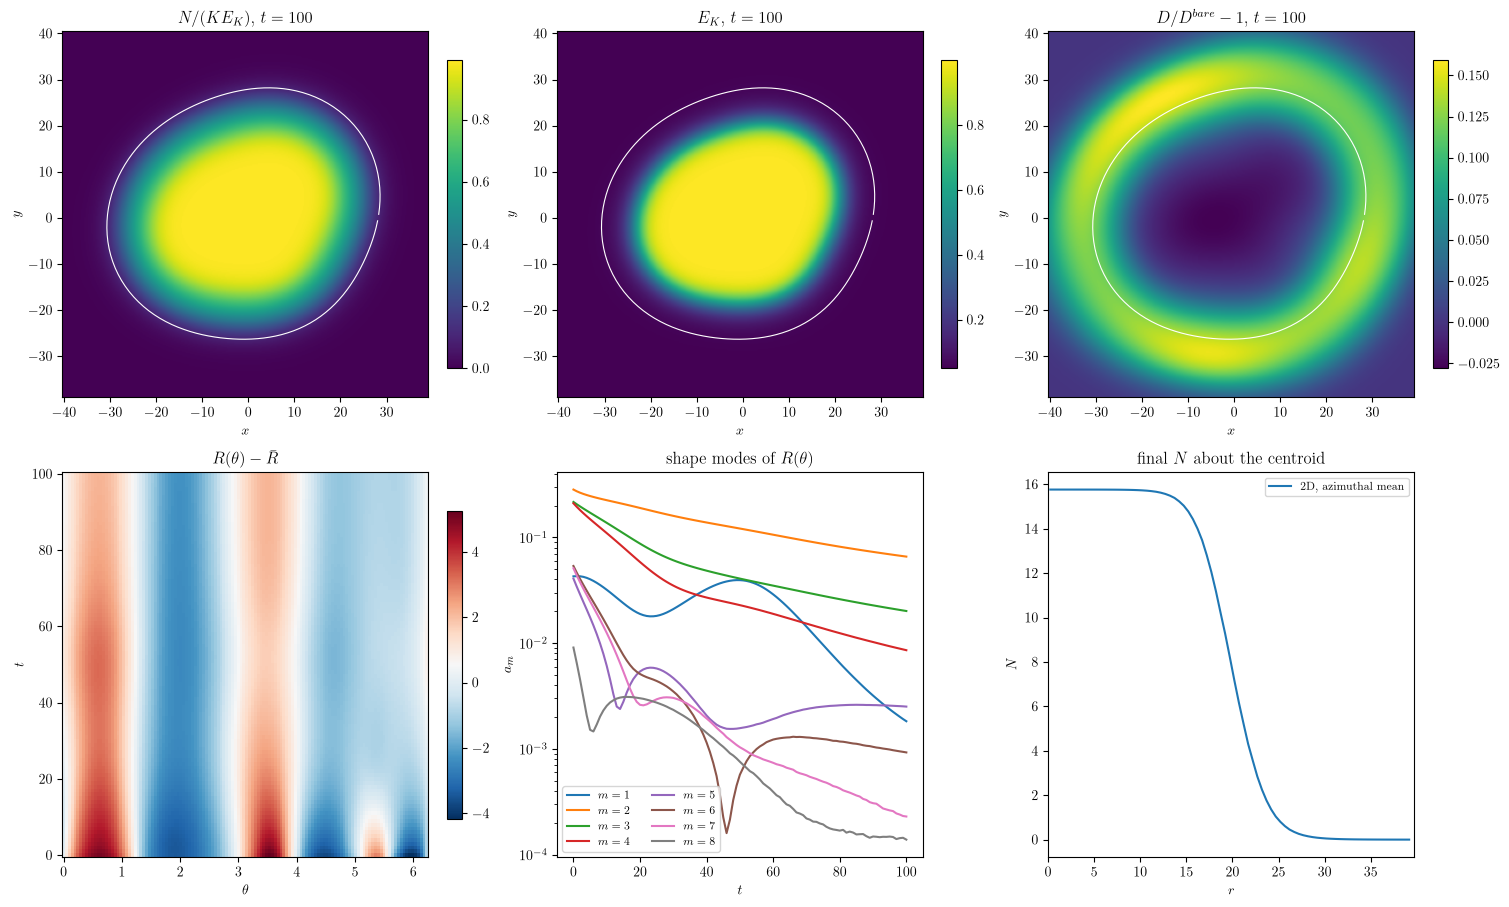

In [92]:
# 2D run: final maps (top) and front shape over time (bottom).
cart_final = cart_storage[-1]
cart_center = np.array([df_cart["cx"].iloc[-1], df_cart["cy"].iloc[-1]])
L = cartesian_dict["half_width"]
extent = [-L, L, -L, L]
zoom = 1.3 * np.nanmax(cart_R[-1]) if np.any(np.isfinite(cart_R[-1])) else L

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
maps = [
    (cart_final[0].data / (cart_params["K"] * cart_final[2].data), r"$N/(KE_K)$"),
    (cart_final[2].data, r"$E_K$"),
    (
        sigmoid_value(cart_final[3].data, cart_params["k0"], cart_params["D0"])
        / cart_preset["D"]
        - 1,
        r"$D/D^{bare}-1$",
    ),
]
front_x = cart_center[0] + cart_R[-1] * np.cos(cart_theta)
front_y = cart_center[1] + cart_R[-1] * np.sin(cart_theta)
for ax, (data, label) in zip(axes[0], maps):
    im = ax.imshow(data.T, origin="lower", extent=extent, cmap="viridis")
    ax.plot(front_x, front_y, color="w", lw=0.8)
    ax.set_xlim(cart_center[0] - zoom, cart_center[0] + zoom)
    ax.set_ylim(cart_center[1] - zoom, cart_center[1] + zoom)
    ax.set(
        xlabel="$x$", ylabel="$y$", title=label + f", $t={df_cart['t'].iloc[-1]:.0f}$"
    )
    fig.colorbar(im, ax=ax, shrink=0.8)

ax = axes[1, 0]
pc = ax.pcolormesh(
    cart_theta,
    df_cart["t"],
    cart_R - df_cart["R_mean"].to_numpy()[:, None],
    cmap="RdBu_r",
    shading="auto",
)
ax.set(xlabel=r"$\theta$", ylabel="$t$", title=r"$R(\theta)-\bar R$")
fig.colorbar(pc, ax=ax, shrink=0.8)

ax = axes[1, 1]
for m in range(1, cartesian_dict["n_modes"] + 1):
    ax.semilogy(df_cart["t"], df_cart[f"a{m}"], label=f"$m={m}$")
ax.set(xlabel="$t$", ylabel="$a_m$", title=r"shape modes of $R(\theta)$")
ax.legend(fontsize=8, ncol=2)

ax = axes[1, 2]
r_edges = np.arange(0.0, zoom, 2 * min(cart_grid.discretization))
r_mid = 0.5 * (r_edges[1:] + r_edges[:-1])
ax.plot(
    r_mid,
    azimuthal_average(cart_final[0].data, cart_grid, cart_center, r_edges),
    label="2D, azimuthal mean",
)
if cartesian_seed is None and "hybrid_scenario_final_profiles" in globals():
    polar_final = {name: N for name, N, *_ in hybrid_scenario_final_profiles}
    if cartesian_preset_name in polar_final:
        polar_r = PolarSymGrid(
            radius=config_dict["integration"]["outer_radius"],
            shape=config_dict["integration"]["num_pts_radius"],
        ).axes_coords[0]
        ax.plot(polar_r, polar_final[cartesian_preset_name], ls="--", label="polar run")
ax.set(
    xlabel="$r$", ylabel="$N$", xlim=(0, zoom), title=r"final $N$ about the centroid"
)
ax.legend(fontsize=8)
plt.show()